# Air Quality: Missing Data and Outliers

Daily New York air-quality readings, May to September 1973 (153 days): ozone (ppb), solar radiation (langley), wind (mph) and temperature (°F).

The notebook answers three practical questions in order:

1. **How much is missing, and is the missingness random?** (It decides which fixes are safe.)
2. **Which imputation method works best?** Evaluated honestly by hiding values that are known, imputing them, and measuring the error.
3. **Which readings are outliers, and does the detection method matter?** With a skewed variable, the answer differs by method.

Nothing is dropped or overwritten silently: flagged outliers stay in the data.

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer, KNNImputer
from sklearn.linear_model import BayesianRidge
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)

## 1. Load and understand the data

In [ ]:
raw = pd.read_csv('../../data/airQuality.csv')
raw['Date'] = pd.to_datetime(dict(year=1973, month=raw.Month, day=raw.Day))
air = raw.set_index('Date')[['Ozone', 'Solar.R', 'Wind', 'Temp']].copy()
air['month'] = air.index.month
print(air.shape, "| date range:", air.index.min().date(), "to", air.index.max().date(),
      "| continuous daily index:", bool((air.index.to_series().diff().dropna() == pd.Timedelta('1D')).all()))
air.head()

(153, 5) | date range: 1973-05-01 to 1973-09-30 | continuous daily index: True


,Ozone,Solar.R,Wind,Temp,month
Date,,,,,
1973-05-01,41.0,190.0,7.4,67,5
1973-05-02,36.0,118.0,8.0,72,5
1973-05-03,12.0,149.0,12.6,74,5
1973-05-04,18.0,313.0,11.5,62,5
1973-05-05,NaN,NaN,14.3,56,5


In [ ]:
nullity = air.drop(columns='month').isnull().sum().to_frame('Missing values')
nullity['% missing'] = (air.drop(columns='month').isnull().mean() * 100).round(2)
nullity

,Missing values,% missing
Ozone,37,24.18
Solar.R,7,4.58
Wind,0,0.00
Temp,0,0.00


### Where is the data missing?

A missingness matrix (dark = present, light = missing) and the share of missing ozone readings per month. Plain matplotlib is used, so no extra dependency is needed.

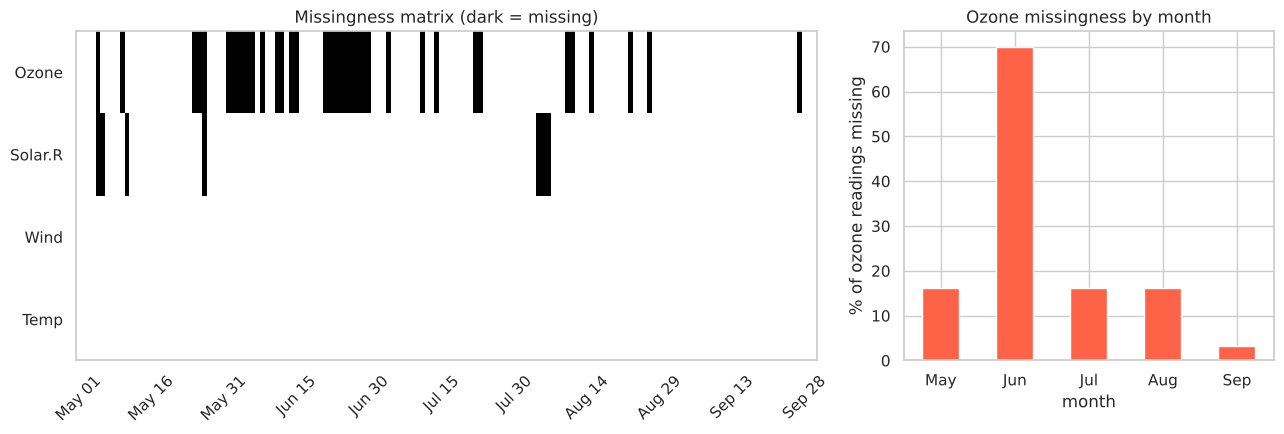

In [ ]:
cols = ['Ozone', 'Solar.R', 'Wind', 'Temp']
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={'width_ratios': [2, 1]})
axes[0].imshow(air[cols].isnull().values.T, aspect='auto', cmap='Greys', interpolation='nearest')
axes[0].set_yticks(range(4)); axes[0].set_yticklabels(cols)
ticks = np.arange(0, len(air), 15)
axes[0].set_xticks(ticks); axes[0].set_xticklabels(air.index[ticks].strftime('%b %d'), rotation=45)
axes[0].set_title('Missingness matrix (dark = missing)'); axes[0].grid(False)

(air.groupby('month')['Ozone'].apply(lambda s: s.isnull().mean() * 100)
    .rename(index={5: 'May', 6: 'Jun', 7: 'Jul', 8: 'Aug', 9: 'Sep'})
    .plot.bar(ax=axes[1], color='tomato', rot=0))
axes[1].set_ylabel('% of ozone readings missing'); axes[1].set_title('Ozone missingness by month')
plt.tight_layout(); plt.show()

### Is the missingness random?

Missing Completely At Random (MCAR) would justify simple fixes; if missingness depends on other variables (MAR) the simple fixes can bias results. For ozone (the only column with substantial missingness), compare the other variables on days when ozone is missing vs present with a Mann-Whitney test, and test whether the missing share differs across months.

In [ ]:
air['ozone_missing'] = air['Ozone'].isnull()
rows = []
for c in ['Solar.R', 'Wind', 'Temp']:
    a, b = air.loc[air.ozone_missing, c].dropna(), air.loc[~air.ozone_missing, c].dropna()
    rows.append((c, a.median(), b.median(), stats.mannwhitneyu(a, b).pvalue))
display(pd.DataFrame(rows, columns=['variable', 'median | ozone missing', 'median | ozone present', 'Mann-Whitney p']).round(4).set_index('variable'))

ct = pd.crosstab(air['month'], air['ozone_missing'])
chi2, p, _, _ = stats.chi2_contingency(ct)
print(f"Missing-by-month chi-square p = {p:.4f}")

Missing-by-month chi-square p = 0.0000


,median | ozone missing,median | ozone present,Mann-Whitney p
variable,,,
Solar.R,194.0,207.0,0.7362
Wind,9.7,9.7,0.4186
Temp,79.0,79.0,0.9405


**Interpretation.** Ozone has about a quarter of its values missing and the gaps are strongly concentrated in time: 21 of June's 30 days are missing (70 %) against 1-5 days in every other month, which looks like an instrument outage rather than random loss. So MCAR is doubtful for ozone (the solar, wind and temperature tests show no difference, but those cannot rule out dependence on time); with n = 153 the tests on the other variables have limited power, so treat their p-values as indications, not proof. Practical consequence: long gaps cannot be filled by interpolating neighbouring days, so prefer methods that use the other variables, and report results with and without imputed rows if a conclusion depends on them.

## 2. Choosing an imputation method

Comparing imputers by eye proves nothing. Instead, the evaluation hides part of the **known** ozone values, imputes them, and measures the error against the true values. Repeated 30 times with different random 20 % masks gives a mean ± std of RMSE.

Candidates:

| Method | Uses |
|---|---|
| Mean / median | ozone only |
| Linear interpolation | neighbouring days (time order) |
| KNN (k = 5) | Solar.R, Wind, Temp, month (standardised) |
| Iterative (BayesianRidge) | Solar.R, Wind, Temp, month |

The imputers only ever see the *masked* table, so there is no leakage of the hidden truth. Caveat: random masking simulates MCAR; if the real gaps are systematic, errors will differ.

In [ ]:
features = ['Ozone', 'Solar.R', 'Wind', 'Temp', 'month']

def impute(table, method):
    t = table[features].copy()
    if method == 'mean':
        return t['Ozone'].fillna(t['Ozone'].mean())
    if method == 'median':
        return t['Ozone'].fillna(t['Ozone'].median())
    if method == 'interpolate (time)':
        return t['Ozone'].interpolate(method='time', limit_direction='both')
    scaler = StandardScaler().fit(t)                              # NaN-aware: statistics use observed values only
    scaled = pd.DataFrame(scaler.transform(t), index=t.index, columns=t.columns)
    if method == 'KNN':
        out = KNNImputer(n_neighbors=5).fit_transform(scaled)
    else:
        out = IterativeImputer(estimator=BayesianRidge(), max_iter=20, random_state=0).fit_transform(scaled)
    # undo the scaling of the Ozone column with the scaler's own statistics, keep observed values untouched
    ozone_imp = pd.Series(out[:, 0] * scaler.scale_[0] + scaler.mean_[0], index=t.index).clip(lower=0)  # ozone cannot be negative
    return t['Ozone'].fillna(ozone_imp)

methods = ['mean', 'median', 'interpolate (time)', 'KNN', 'iterative']
known_idx = air.index[air['Ozone'].notna()]
rng = np.random.default_rng(0)
errs = {m: [] for m in methods}
maes = {m: [] for m in methods}
for _ in range(30):
    hide = rng.choice(known_idx, size=int(0.2 * len(known_idx)), replace=False)
    masked = air.copy()
    masked.loc[hide, 'Ozone'] = np.nan
    truth = air.loc[hide, 'Ozone']
    for m in methods:
        pred = impute(masked, m).loc[hide]
        errs[m].append(np.sqrt(np.mean((pred - truth) ** 2)))
        maes[m].append(np.mean(np.abs(pred - truth)))

result = pd.DataFrame({'RMSE mean': {m: np.mean(v) for m, v in errs.items()},
                       'RMSE std': {m: np.std(v) for m, v in errs.items()},
                       'MAE mean': {m: np.mean(v) for m, v in maes.items()}}).sort_values('RMSE mean')
result.round(2)

,RMSE mean,RMSE std,MAE mean
KNN,18.31,3.65,13.59
iterative,18.98,4.01,14.39
interpolate (time),27.48,4.39,20.74
mean,30.69,4.73,25.66
median,31.80,5.26,24.03


Best method by RMSE: KNN


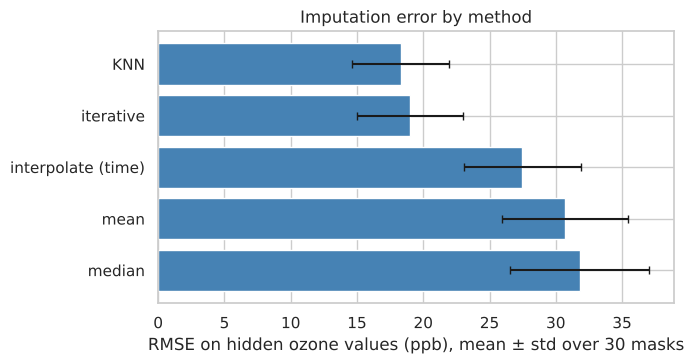

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.8))
order = result.index
ax.barh(order[::-1], result['RMSE mean'][::-1], xerr=result['RMSE std'][::-1], color='steelblue', capsize=3)
ax.set_xlabel('RMSE on hidden ozone values (ppb), mean ± std over 30 masks'); ax.set_title('Imputation error by method')
plt.tight_layout(); plt.show()
best = result.index[0]
print("Best method by RMSE:", best)

**Reading the result.** Model-based methods that use temperature and wind (and the seasonal pattern) are expected to beat mean/median filling, because ozone is strongly related to both. Time interpolation helps only when gaps are short; here many gaps are long (a nearly month-long hole in June), which is why it trails the model-based methods. The std column shows how much the ranking can move between masks; methods within about one std of each other should be treated as equivalent. Note also that mean/median filling shrinks the variance of the filled column, so any downstream analysis of spread would be biased; the check below shows this.

In [ ]:
filled = {m: impute(air, m) for m in methods}
summary = pd.DataFrame({'observed only': air['Ozone'].describe()[['mean', 'std', 'min', 'max']]})
for m, s in filled.items():
    summary[m] = s.describe()[['mean', 'std', 'min', 'max']]
summary.round(1)

,observed only,mean,median,interpolate (time),KNN,iterative
mean,42.1,42.1,39.6,43.3,41.2,42.5
std,33.0,28.7,29.1,31.9,30.1,30.4
min,1.0,1.0,1.0,1.0,1.0,0.0
max,168.0,168.0,168.0,168.0,168.0,168.0


In [ ]:
air['Ozone_imputed'] = filled[best]
air['ozone_was_missing'] = air['Ozone'].isnull()
print(f"Added 'Ozone_imputed' using '{best}' and a flag column for the {int(air.ozone_was_missing.sum())} imputed rows.")
air[['Ozone', 'Ozone_imputed', 'ozone_was_missing']].head(8)

Added 'Ozone_imputed' using 'KNN' and a flag column for the 37 imputed rows.


,Ozone,Ozone_imputed,ozone_was_missing
Date,,,
1973-05-01,41.0,41.0,False
1973-05-02,36.0,36.0,False
1973-05-03,12.0,12.0,False
1973-05-04,18.0,18.0,False
1973-05-05,NaN,23.0,True
1973-05-06,28.0,28.0,False
1973-05-07,23.0,23.0,False
1973-05-08,19.0,19.0,False


## 3. Outlier analysis

Outliers are detected on the **observed** ozone readings (imputed values must not be used to decide what is unusual). Ozone is right-skewed, which breaks the assumptions of some detectors. Three standard rules are compared, each on the raw scale and after a `log1p` transform:

- **IQR rule:** outside Q1 - 1.5·IQR, Q3 + 1.5·IQR
- **Z-score:** |z| > 3 (assumes roughly normal data)
- **MAD (modified z-score):** > 3.5 (robust to extremes)

In [ ]:
def flag_iqr(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return (s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)

def flag_z(s, thr=3):
    return (np.abs(stats.zscore(s)) > thr)

def flag_mad(s, thr=3.5):
    med = np.median(s); mad = stats.median_abs_deviation(s)
    return pd.Series(np.abs(0.6745 * (s - med) / mad) > thr, index=s.index)

obs = air['Ozone'].dropna()
variants = {'raw': obs, 'log1p': np.log1p(obs)}
counts = {}
flags = {}
for vname, s in variants.items():
    for fname, f in [('IQR', flag_iqr), ('Z-score', flag_z), ('MAD', flag_mad)]:
        fl = pd.Series(f(s), index=s.index)
        flags[(vname, fname)] = fl
        counts[(vname, fname)] = int(fl.sum())
pd.Series(counts, name='outliers flagged').unstack().round(0)

,IQR,MAD,Z-score
log1p,1,0,1
raw,2,2,1


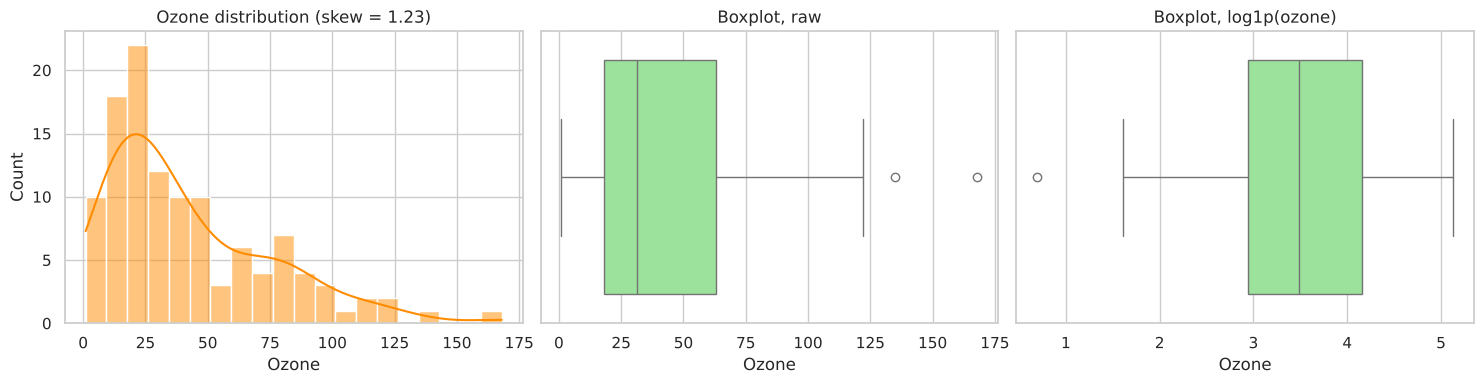

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(obs, bins=20, kde=True, ax=axes[0], color='darkorange'); axes[0].set_title(f'Ozone distribution (skew = {stats.skew(obs):.2f})')
sns.boxplot(x=obs, ax=axes[1], color='lightgreen'); axes[1].set_title('Boxplot, raw')
sns.boxplot(x=np.log1p(obs), ax=axes[2], color='lightgreen'); axes[2].set_title('Boxplot, log1p(ozone)')
plt.tight_layout(); plt.show()

Days flagged by the raw IQR rule:
Date
1973-08-25    168.0
1973-07-01    135.0


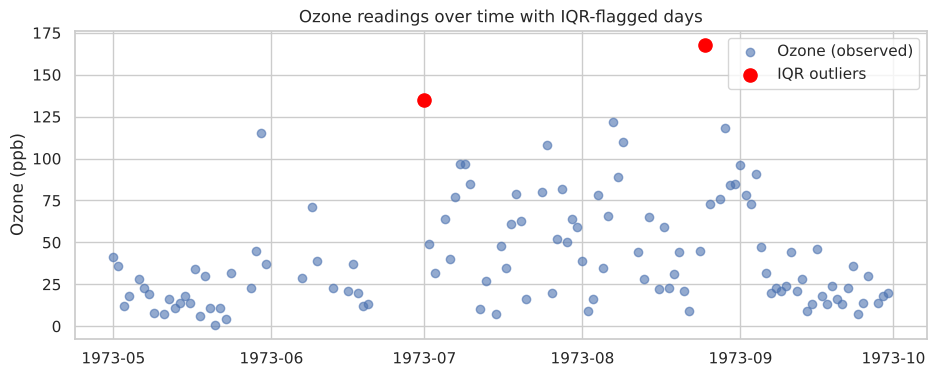

In [ ]:
iqr_out = obs[flags[('raw', 'IQR')]]
print("Days flagged by the raw IQR rule:")
print(iqr_out.sort_values(ascending=False).to_string())

plt.figure(figsize=(11, 4))
plt.scatter(obs.index, obs, alpha=0.6, label='Ozone (observed)')
plt.scatter(iqr_out.index, iqr_out, color='red', s=90, label='IQR outliers')
plt.ylabel('Ozone (ppb)'); plt.title('Ozone readings over time with IQR-flagged days'); plt.legend(); plt.show()

**Reading the results.**
- On the raw scale, the right-skew produces a handful of high readings that the IQR rule flags; the z-score rule flags fewer (extreme values inflate the standard deviation that z uses, which masks them).
- After a log transform the distribution is far more symmetric (skew falls from about +1.2 to -0.3) and **both upper-tail flags disappear**; the only remaining flag is a single very low day (1 ppb). The two high days (1 July and 25 August, 135 and 168 ppb) are the long tail of a skewed variable, not obvious errors; high ozone in summer heat is physically plausible.
- **Recommendation:** do not delete these days. Keep them, flag them, and use robust or log-scale statistics if they distort a model.

### Same check for the other variables
Temperature and solar radiation have no flags. Wind has three high-wind days under the IQR rule (9 May, 18 May, 17 June), one under the z-score and none under MAD: the detectors disagree on borderline values, which is normal and a reminder to inspect flagged points rather than delete them automatically.

In [ ]:
for col in ['Wind', 'Temp', 'Solar.R']:
    s = air[col].dropna()
    print(f"{col:8s} skew={stats.skew(s):+.2f} | IQR flags={int(flag_iqr(s).sum())} | z>3 flags={int(flag_z(s).sum())} | MAD flags={int(flag_mad(s).sum())}")

Wind     skew=+0.34 | IQR flags=3 | z>3 flags=1 | MAD flags=0
Temp     skew=-0.37 | IQR flags=0 | z>3 flags=0 | MAD flags=0
Solar.R  skew=-0.42 | IQR flags=0 | z>3 flags=0 | MAD flags=0


## Methodology notes

- **Imputation was validated, not assumed:** methods were compared by masking known values and measuring error, repeated 30 times. A single random mask would give a different winner by chance.
- **Missingness was tested:** MCAR is doubtful for ozone, so imputed rows are flagged (`ozone_was_missing`) and the raw column is kept alongside the imputed one.
- **No leakage:** imputers see only the masked table; outliers are detected on observed values only.
- **Outliers are flagged, not removed**, and the detector is chosen for the distribution (log scale for skewed ozone).
- **Limits:** 153 rows from one summer in one city. Findings illustrate the workflow; the numbers do not generalise to other sites or years.